# Chapitre 9 - Cours 3 : validation atomique et transactions distribuées (2PC)

Ce notebook couvre la partie *Atomic Commit and Two-Phase Commit (2PC)* de la section
*Distributed Transactions and Consensus* (*From single-node to distributed atomic
commit*, *Introduction to two-phase commit*, *A system of promises*, *Coordinator
failure*, *Three-phase commit*) et la partie *Distributed Transactions in Practice*
(*Exactly-once message processing*, *XA transactions*, *Holding locks while in doubt*,
*Recovering from coordinator failure*, *Limitations of distributed transactions*). Les
transactions sur un seul nœud (ACID, isolation) ont été étudiées au chapitre
7 ; le consensus tolérant aux pannes, qui permet de dépasser les limites
de 2PC, est l'objet du cours suivant.

**Plan.**

1. De la validation locale à la validation distribuée.
2. Le protocole de validation à deux phases.
3. Un système de promesses : 2PC face aux pannes.
4. La panne du coordinateur : participants en doute.
5. Pourquoi ne pas décider seul ? (validation à trois phases).
6. Transactions distribuées hétérogènes et XA.
7. Verrous tenus en doute et reprise après panne.
8. Les limites des transactions XA.

Le protocole est simulé sur le simulateur à événements discrets `ddia.sim` (réseau
asynchrone, pannes de nœuds), avec les classes `Coordinator2PC` et `Participant2PC` de
[`ddia/transactions.py`](../../ddia/transactions.py) ; la fonction `run_2pc` lance une
transaction et renvoie la trace des messages et une synthèse par participant.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import run_2pc, Participant2PC
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)

COULEUR_MSG = {"begin": SLATE, "prepare": INDIGO, "vote": VIOLET, "commit": GREEN, "abort": ROSE,
               "ack": GRAY, "status?": AMBER, "status": AMBER, "commit1": GREEN}


def frise(run, title, subtitle=None, t_max=None, width=11, labels=True):
    """Diagramme espace-temps d'une exécution de run_2pc : messages, verrous (bande
    sarcelle), période en doute (bande ambre), pannes et décisions."""
    noms = ["coord"] + [p.name for p in run.parts]
    t_max = t_max or run.t_max
    st = SpaceTime(noms, t_max=t_max, title=None, subtitle=subtitle, width=width,
                   time_label="temps (unités arbitraires)")
    st.ax.set_title(title, pad=18 if subtitle else 6)
    for p in run.parts:
        if p.lock_from is not None:
            fin = p.lock_until if p.lock_until is not None else t_max
            st.span(p.name, p.lock_from, fin, "", color=TEAL, alpha=0.15)
        if p.prepared_at is not None:
            fin = p.decided_at if p.decided_at is not None else t_max
            st.span(p.name, p.prepared_at, fin, "en doute", color=AMBER, alpha=0.3)
        if p.outcome:
            st.event(p.name, p.decided_at, p.outcome, kind="star",
                     color=GREEN if p.outcome == "commit" else ROSE)
    for d in run.net.trace:
        if d.t_send > t_max:
            continue
        kind = d.msg[0]
        lab = "/".join(str(x) for x in d.msg) if labels else ""
        lab = {"vote/yes": "oui", "vote/no": "non", "ack/commit": "ack", "ack/abort": "ack",
               "commit1": "commit"}.get(lab, lab)
        st.msg(d.src, d.t_send, d.dst, min(d.t_recv, t_max), lab, color=COULEUR_MSG.get(kind, SLATE),
               lost=d.lost, fontsize=7.5)
    for node in [run.coord] + run.parts:
        for t, what in node.log:
            if what == "panne":
                st.event(node.name, t, "panne", kind="crash")
            elif what == "redémarrage":
                st.event(node.name, t, "redémarrage", kind="tick")
            elif what.startswith("décision"):
                st.event(node.name, t, "", kind="point", color=INDIGO)
                st.note(t, node.name, what.replace(" journalisée", ""), dy=0.28, color=INDIGO, fontsize=8)
    return st

## 1. De la validation locale à la validation distribuée (section *From single-node to distributed atomic commit*)

Sur un seul nœud, l'atomicité tient à l'ordre des écritures sur disque : d'abord les
données, puis le **record de validation** (cours 1 du chapitre 7). Le moment où
le contrôleur d'**un** disque finit d'écrire ce record décide de tout : avant, la
transaction peut encore disparaître ; après, elle est validée.

Une transaction **distribuée** touche plusieurs nœuds : plusieurs partitions d'une base,
ou un index secondaire global stocké ailleurs que la donnée. Envoyer simplement « valide »
à chaque nœud ne suffit pas : un nœud peut détecter une violation de contrainte et
refuser, une requête peut se perdre, un nœud peut tomber avant d'écrire son record. Et
une fois validée sur un nœud, une transaction ne peut plus être retirée : d'autres
transactions ont pu lire ses données (*read committed*). Simulons cette **validation
naïve en une phase**, où le second participant viole une contrainte.

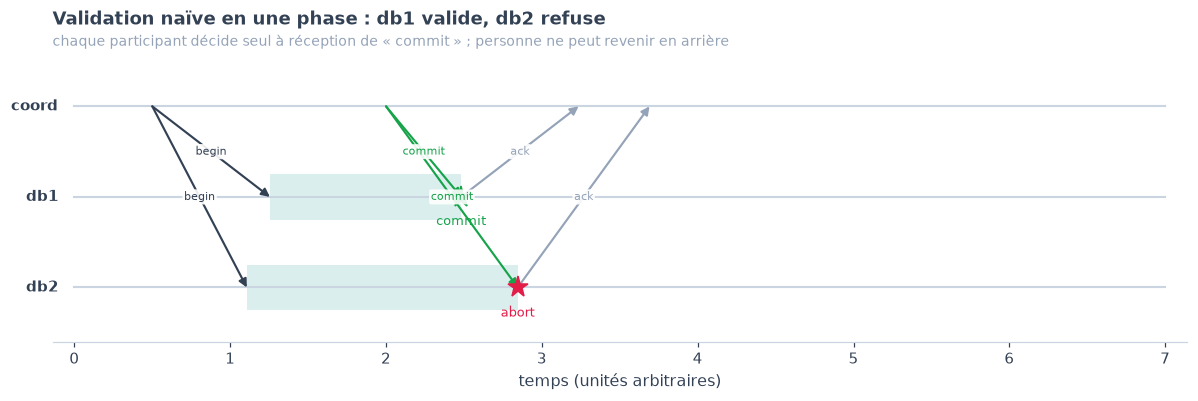

,participant,vote,issue
0,db1,yes,commit
1,db2,no,abort


In [2]:
naif = run_2pc(protocol="1pc", votes=["yes", "no"], t_max=7)
frise(naif, "Validation naïve en une phase : db1 valide, db2 refuse",
      "chaque participant décide seul à réception de « commit » ; personne ne peut revenir en arrière").show()
naif.summary[["participant", "vote", "issue"]]

db1 a validé, db2 a annulé : la transaction est **à moitié faite**, et l'atomicité est
perdue. Il faut que tous les participants valident, ou que tous annulent : c'est le
problème de la **validation atomique** (*atomic commitment*).

> **À retenir.** Sur un nœud, un seul disque prend la décision. Sur plusieurs nœuds,
> chacun peut échouer indépendamment : il faut un protocole pour que tous décident la
> même chose.

## 2. Le protocole de validation à deux phases (section *Introduction to two-phase commit*)

La **validation à deux phases** (2PC) est l'algorithme classique de validation atomique
entre plusieurs nœuds. Elle introduit un nouveau rôle, le **coordinateur** (ou
gestionnaire de transactions), souvent une bibliothèque dans le processus de
l'application (Narayana, JOTM, BTM, MSDTC...). Les nœuds de la base sont les
**participants**. Quand l'application veut valider :

- **phase 1** : le coordinateur envoie `prepare` à chaque participant, qui répond oui ou
  non ;
- **phase 2** : si tous ont dit oui, le coordinateur envoie `commit` ; sinon `abort`.

Le livre compare cela à une cérémonie de mariage : l'officier demande à chacun s'il
consent, et ne prononce l'union que si les deux ont dit oui.

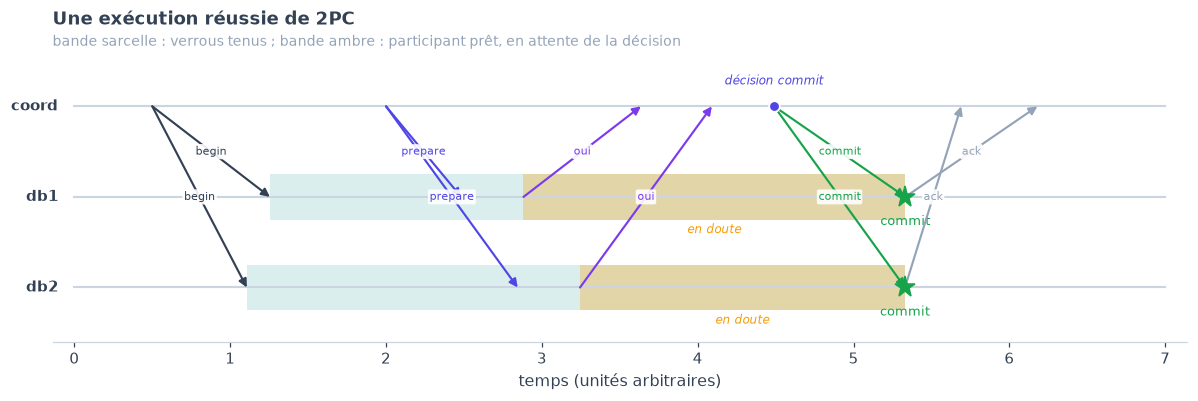

,participant,vote,issue,verrous_de,verrous_jusqu_à,durée_verrous,durée_en_doute
0,db1,yes,commit,1.25,5.33,4.08,2.45
1,db2,yes,commit,1.11,5.33,4.22,2.09


In [3]:
ok = run_2pc(t_max=7)
frise(ok, "Une exécution réussie de 2PC",
      "bande sarcelle : verrous tenus ; bande ambre : participant prêt, en attente de la décision").show()
ok.summary

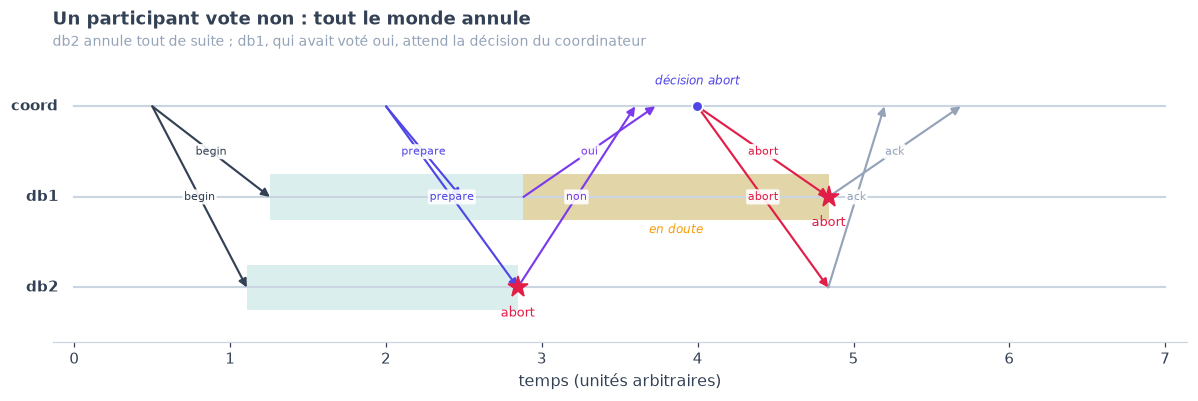

In [4]:
non = run_2pc(votes=["yes", "no"], t_max=7)
frise(non, "Un participant vote non : tout le monde annule",
      "db2 annule tout de suite ; db1, qui avait voté oui, attend la décision du coordinateur").show()

**Le coût.** Par rapport à une validation locale, 2PC ajoute deux allers-retours réseau
(préparation, décision) et des écritures durables (`fsync`) : chaque participant écrit
ses données et son vote avant de répondre oui, le coordinateur écrit sa décision avant de
la diffuser. Pour $n$ participants : $4n$ messages (dont $n$ accusés de réception
facultatifs pour la latence), $n + 1$ `fsync` sur le chemin critique, et des verrous
tenus pendant tout ce temps (bandes sarcelle). C'est une grande partie de la réputation
de lenteur des transactions distribuées.

> **À retenir.** 2PC sépare la validation en un vote (phase 1) et une décision (phase 2),
> prise par le coordinateur : commit seulement si tout le monde a voté oui.